# Machine Learning — Practical Session 1## Python for Data Exploration and Preprocessing**National Higher School of Advanced Technologies**  **Academic year: 2026–2027 | First-year master's degree**---**Learning Objectives:** Load and inspect datasets, select features, create training and test sets, explore text data, identify and handle missing values, scale numerical features, and encode categorical variables using pandas, scikit-learn, and seaborn.

## Setup — Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_20newsgroups
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler,
    Normalizer, Binarizer, OrdinalEncoder, LabelEncoder, OneHotEncoder,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")

DATA_DIR = "../../data/"
RESULTS_DIR = "results/"

import os
os.makedirs(RESULTS_DIR, exist_ok=True)

print("All libraries loaded successfully ✅")

All libraries loaded successfully ✅


---# Exercise 1 — Exploring a Tabular Dataset and Creating Data Splits**Dataset:** `Iris_Dataset.csv`

### 1. Load the CSV file into a pandas DataFrame named D

In [2]:
D = pd.read_csv(DATA_DIR + "Iris_Dataset.csv")
print(f"Dataset loaded. Type: {type(D)}")
print(f"Shape: {D.shape}")

Dataset loaded. Type: <class 'pandas.DataFrame'>
Shape: (150, 5)


### 2. Inspect the datasetUsing `info()`, `describe()`, `shape`, `columns`, and `head()`.

In [3]:
# shape — number of rows and columns
print("shape:", D.shape)
print("→ The dataset has 150 observations (rows) and 5 variables (columns).\n")

# columns — variable names
print("columns:", list(D.columns))
print("→ These are the feature/variable names in the dataset.\n")

# head() — first 5 rows
print("head():")
D.head()

shape: (150, 5)
→ The dataset has 150 observations (rows) and 5 variables (columns).

columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
→ These are the feature/variable names in the dataset.

head():


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
# info() — data types and non-null counts
D.info()
print("\n→ All 4 numeric features are float64; 'species' is object (string).")
print("→ No missing values (150 non-null for each column).")

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB

→ All 4 numeric features are float64; 'species' is object (string).
→ No missing values (150 non-null for each column).


In [5]:
# describe() — summary statistics
D.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


> **Explanation:**  > - `shape`: tells us the dataset has 150 samples and 5 variables.  > - `columns`: lists all variable names.  > - `head()`: shows the first 5 rows for a quick look at the data format.  > - `info()`: reveals data types and confirms there are no missing values.  > - `describe()`: provides summary statistics (count, mean, std, min, quartiles, max) for numerical columns — useful for spotting outliers and understanding value ranges.

### 3. Select `sepal_length` and `petal_width` into a new DataFrame

In [6]:
D_selected = D[["sepal_length", "petal_width"]]
D_selected.head()

,sepal_length,petal_width
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2


### 4. Display the first 20 observations

In [7]:
D_selected.head(20)

,sepal_length,petal_width
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2
5,5.4,0.4
6,4.6,0.3
7,5.0,0.2
8,4.4,0.2
9,4.9,0.1


### 5. Create a copy of the original DataFrame

In [8]:
D_copy = D.copy()
print("Copy created using D.copy()")

Copy created using D.copy()


> **Why use a copy?**  > - A copy ensures the original DataFrame remains unchanged.  > - Without `.copy()`, modifications on a slice may alter the original data (due to pandas' view-vs-copy behavior).  > - This is essential when experimenting with preprocessing steps: we can always go back to the original data if something goes wrong.

### 6 & 7. Split the data into training (80%) and test (20%) sets

In [9]:
# Separate features (X) and target (y)
X = D.drop("species", axis=1)  # Input features
y = D["species"]               # Target variable

print("Input features (X):", list(X.columns))
print("Target variable (y): species")
print()

# Split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("stratify=y is used because 'species' is a class label,")
print("ensuring each class is proportionally represented in both sets.")

Input features (X): ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Target variable (y): species

stratify=y is used because 'species' is a class label,
ensuring each class is proportionally represented in both sets.


### 8. Verify the number and proportion of observations

In [10]:
print(f"Total samples:    {len(D)}")
print(f"Training samples: {len(X_train)} ({len(X_train)/len(D)*100:.1f}%)")
print(f"Test samples:     {len(X_test)} ({len(X_test)/len(D)*100:.1f}%)")
print(f"\nTraining set class distribution:")
print(y_train.value_counts())
print(f"\nTest set class distribution:")
print(y_test.value_counts())

Total samples:    150
Training samples: 120 (80.0%)
Test samples:     30 (20.0%)

Training set class distribution:
species
Iris-setosa        40
Iris-virginica     40
Iris-versicolor    40
Name: count, dtype: int64

Test set class distribution:
species
Iris-setosa        10
Iris-virginica     10
Iris-versicolor    10
Name: count, dtype: int64


> **Discussion — Why keep the test set separate?**  > - The test set simulates unseen data to evaluate generalization.  > - If test data influences preprocessing or model selection, the model effectively "sees" the answers, leading to overly optimistic performance estimates (**data leakage**).  > - Example: if we compute the mean/std for scaling using the entire dataset (including test), the model gains information about the test distribution, resulting in biased evaluation.  > - The test set should only be used once: for the final evaluation.

---# Exercise 2 — Exploring Text Data**Files:** `txt_file.txt` and scikit-learn's 20 Newsgroups dataset

### 1. Open and read `txt_file.txt`

In [11]:
with open(DATA_DIR + "txt_file.txt", "r", encoding="utf-8") as f:
    content = f.read()
print(content)

0.50,0.20,0.84,0.01,c1
0.10,0.10,0.40,0.02,c2
0.15,0.10,0.45,0.03,c2
0.22,0.20,0.90,0.01,c1
0.25,0.20,0.87,0.01,c1
0.10,0.10,0.38,0.02,c2



### 2. Iterate through the file and display each line

In [12]:
with open(DATA_DIR + "txt_file.txt", "r", encoding="utf-8") as f:
    for i, line in enumerate(f, 1):
        # Remove only the trailing newline character
        print(f"Line {i}: {line.rstrip(chr(10))}")

Line 1: 0.50,0.20,0.84,0.01,c1
Line 2: 0.10,0.10,0.40,0.02,c2
Line 3: 0.15,0.10,0.45,0.03,c2
Line 4: 0.22,0.20,0.90,0.01,c1
Line 5: 0.25,0.20,0.87,0.01,c1
Line 6: 0.10,0.10,0.38,0.02,c2


### 3. Load the 20 Newsgroups dataset

In [13]:
newsgroups_train = fetch_20newsgroups(subset="train")
print("20 Newsgroups training dataset loaded successfully.")

20 Newsgroups training dataset loaded successfully.


### 4. Number of documents and labels

In [14]:
n_documents = len(newsgroups_train.data)
n_labels = len(newsgroups_train.target_names)

print(f"Number of documents: {n_documents}")
print(f"Number of label categories: {n_labels}")
print()
print("→ Each document is a text sample (a newsgroup post).")
print("→ Each label represents the newsgroup category the document belongs to.")

Number of documents: 11314
Number of label categories: 20

→ Each document is a text sample (a newsgroup post).
→ Each label represents the newsgroup category the document belongs to.


### 5. Display the first document and its target label

In [15]:
print("First document (truncated to 500 chars):")
print("-" * 60)
print(newsgroups_train.data[0][:500])
print("-" * 60)
print(f"\nTarget label (numeric): {newsgroups_train.target[0]}")
print(f"Target label (name):    {newsgroups_train.target_names[newsgroups_train.target[0]]}")

First document (truncated to 500 chars):
------------------------------------------------------------
From: lerxst@wam.umd.edu (where's my thing)
Subject: WHAT car is this!?
Nntp-Posting-Host: rac3.wam.umd.edu
Organization: University of Maryland, College Park
Lines: 15

 I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a m
------------------------------------------------------------

Target label (numeric): 7
Target label (name):    rec.autos


### 6. Display class names and explain the mapping

In [16]:
print("Available class names:")
for i, name in enumerate(newsgroups_train.target_names):
    print(f"  {i:2d} → {name}")

Available class names:
   0 → alt.atheism
   1 → comp.graphics
   2 → comp.os.ms-windows.misc
   3 → comp.sys.ibm.pc.hardware
   4 → comp.sys.mac.hardware
   5 → comp.windows.x
   6 → misc.forsale
   7 → rec.autos
   8 → rec.motorcycles
   9 → rec.sport.baseball
  10 → rec.sport.hockey
  11 → sci.crypt
  12 → sci.electronics
  13 → sci.med
  14 → sci.space
  15 → soc.religion.christian
  16 → talk.politics.guns
  17 → talk.politics.mideast
  18 → talk.politics.misc
  19 → talk.religion.misc


> **Explanation:**  > - Numeric target values are integer indices (0 to 19).  > - Each integer maps to a class name via `target_names[i]`.  > - This encoding is necessary because ML algorithms work with numbers, not strings.  > - The integer itself has no ordinal meaning here — it is just an arbitrary label.

### 7. (Optional) Compare document lengths

Min length:    125 chars
Max length:    75154 chars
Mean length:   1949 chars


Median length: 1178 chars


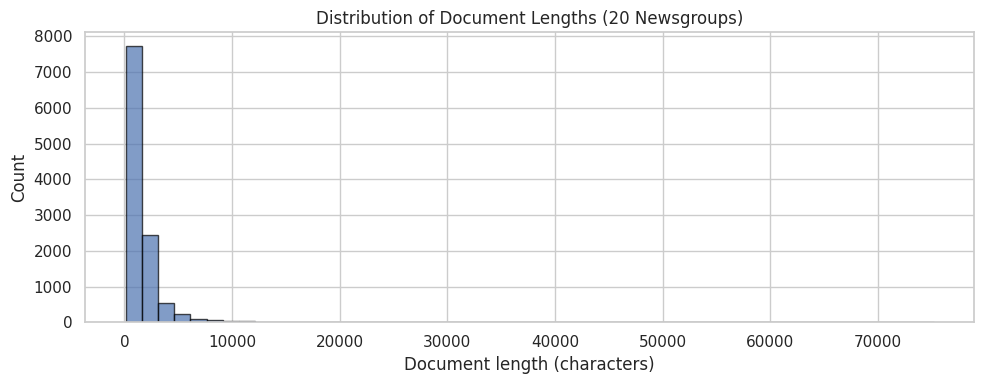

In [17]:
doc_lengths = [len(doc) for doc in newsgroups_train.data]

print(f"Min length:    {min(doc_lengths)} chars")
print(f"Max length:    {max(doc_lengths)} chars")
print(f"Mean length:   {np.mean(doc_lengths):.0f} chars")
print(f"Median length: {np.median(doc_lengths):.0f} chars")

plt.figure(figsize=(10, 4))
plt.hist(doc_lengths, bins=50, edgecolor='black', alpha=0.7)
plt.title("Distribution of Document Lengths (20 Newsgroups)")
plt.xlabel("Document length (characters)")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(RESULTS_DIR + "doc_lengths_distribution.png", dpi=150)
plt.show()

---# Exercise 3 — Detecting and Handling Missing Values**Dataset:** `employees.csv`

### 1. Load and inspect `employees.csv`

In [18]:
employees = pd.read_csv(DATA_DIR + "employees.csv")
print(f"Shape: {employees.shape}")
print(f"Columns: {list(employees.columns)}")
print(f"\nData types:")
print(employees.dtypes)
print(f"\nFirst 5 rows:")
employees.head()

Shape: (1000, 8)
Columns: ['First Name', 'Gender', 'Start Date', 'Last Login Time', 'Salary', 'Bonus %', 'Senior Management', 'Team']

Data types:
First Name               str
Gender                   str
Start Date               str
Last Login Time          str
Salary                 int64
Bonus %              float64
Senior Management     object
Team                     str
dtype: object

First 5 rows:


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services


### 2. Count missing values per column

In [19]:
missing_before = employees.isna().sum()
print("Missing values per column:")
print(missing_before)

Missing values per column:
First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 0
Bonus %                0
Senior Management     67
Team                  43
dtype: int64


### 3. Visualize missing-value patterns with a heatmap

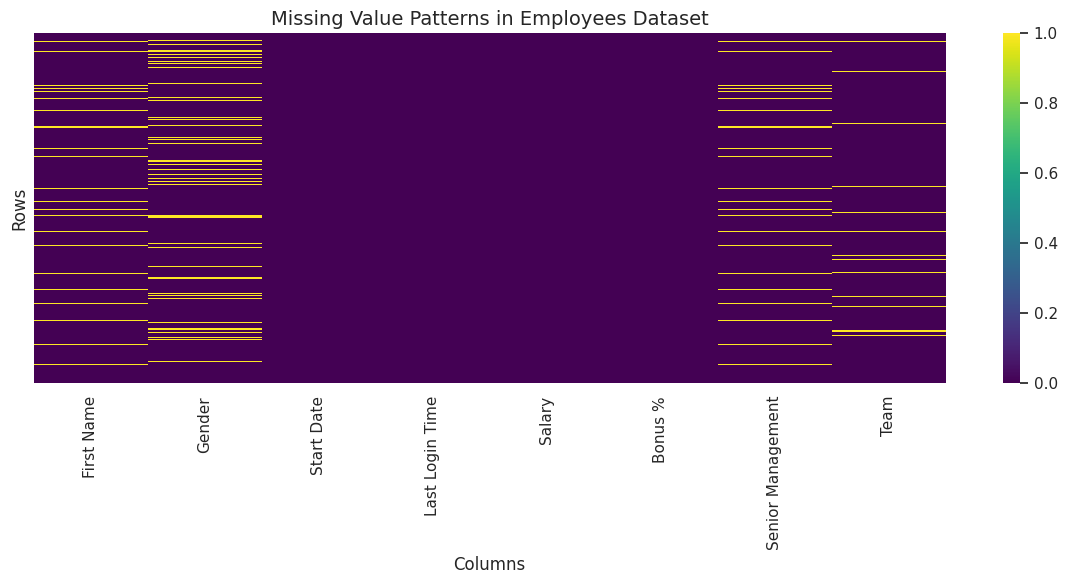

In [20]:
plt.figure(figsize=(12, 6))
sns.heatmap(employees.isna(), cbar=True, yticklabels=False, cmap="viridis")
plt.title("Missing Value Patterns in Employees Dataset", fontsize=14)
plt.xlabel("Columns", fontsize=12)
plt.ylabel("Rows", fontsize=12)
plt.tight_layout()
plt.savefig(RESULTS_DIR + "missing_values_heatmap.png", dpi=150)
plt.show()

### 4. Create a copy and append a synthetic row

In [21]:
employees_copy = employees.copy()

# Append a synthetic row with '-' as first name and 'na' as gender
synthetic_row = pd.DataFrame([{
    "First Name": "-",
    "Gender": "na",
    "Start Date": np.nan,
    "Last Login Time": np.nan,
    "Salary": np.nan,
    "Bonus %": np.nan,
    "Senior Management": np.nan,
    "Team": np.nan,
}])
employees_copy = pd.concat([employees_copy, synthetic_row], ignore_index=True)

print(f"New shape: {employees_copy.shape}")
print(f"\nLast row:")
employees_copy.tail(1)

New shape: (1001, 8)

Last row:


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
1000,-,na,NaN,NaN,NaN,NaN,NaN,NaN


### 5. Recount missing values — explain why '-' and 'na' are not treated as missing

In [22]:
print("Missing values after adding synthetic row:")
print(employees_copy.isna().sum())

Missing values after adding synthetic row:
First Name            67
Gender               145
Start Date             1
Last Login Time        1
Salary                 1
Bonus %                1
Senior Management     68
Team                  44
dtype: int64


> **Explanation:**  > - `'-'` and `'na'` (lowercase) are **not** automatically treated as missing by pandas because:  >   - pandas only recognizes specific markers as NaN during CSV reading (e.g., empty strings, `'NaN'`, `'NA'`, `'N/A'`, `'null'`, etc.).  >   - `'-'` is a regular string character.  >   - `'na'` in lowercase is also treated as a regular string by default (though `'NA'` uppercase IS recognized).  > - Custom missing-value markers must be explicitly handled.

### 6. Convert markers to `np.nan`

In [23]:
# Define markers to treat as missing (case-consistent rule)
missing_markers = ["-", "na", "NA", "N/A", "n/a", ""]

# Replace these markers with np.nan
employees_copy.replace(missing_markers, np.nan, inplace=True)

print("Converted '-', 'na', and other markers to np.nan.")
print("\nMissing values after conversion:")
print(employees_copy.isna().sum())

Converted '-', 'na', and other markers to np.nan.

Missing values after conversion:
First Name            68
Gender               146
Start Date             1
Last Login Time        1
Salary                 1
Bonus %                1
Senior Management     68
Team                  44
dtype: int64


### 7. Impute missing values using SimpleImputer

In [24]:
# Separate columns by type
categorical_cols = ["First Name", "Gender", "Start Date", "Last Login Time",
                    "Senior Management", "Team"]
numerical_cols = ["Salary", "Bonus %"]

# Impute categorical columns with most_frequent strategy
cat_imputer = SimpleImputer(strategy="most_frequent")
employees_copy[categorical_cols] = cat_imputer.fit_transform(
    employees_copy[categorical_cols]
)

# Impute numerical columns with median strategy
num_imputer = SimpleImputer(strategy="median")
employees_copy[numerical_cols] = num_imputer.fit_transform(
    employees_copy[numerical_cols]
)

print("Imputation complete.")

Imputation complete.


### 8. Compare before and after imputation

In [25]:
missing_after = employees_copy.isna().sum()
comparison = pd.DataFrame({
    "Before (original)": missing_before,
    "After imputation": missing_after,
})
print(comparison)

                   Before (original)  After imputation
First Name                        67                 0
Gender                           145                 0
Start Date                         0                 0
Last Login Time                    0                 0
Salary                             0                 0
Bonus %                            0                 0
Senior Management                 67                 0
Team                              43                 0


> **Limitations of imputation:**  > - Imputation introduces artificial values that may not reflect reality.  > - `most_frequent` for names is meaningless (assigning someone else's name).  > - `median` for salary assumes the missing values follow the same distribution as observed values — this may not be true.  > - Imputation reduces variance and can distort correlations.  >  > **Important:** In a real ML pipeline, fit the imputer **only on training data**, then transform both training and test data with the same fitted imputer to prevent data leakage.

---# Exercise 4 — Feature Scaling, Binarization, and Categorical Encoding## Part A — Scaling and Binarization

In [26]:
# Define the numerical matrix
matrix = np.array([
    [1, -1, 2],
    [2,  0, 0],
    [0,  1, -1]
])

print("Original matrix:")
print(matrix)

Original matrix:
[[ 1 -1  2]
 [ 2  0  0]
 [ 0  1 -1]]


### 1 & 2. Apply scalers and display results

In [27]:
# StandardScaler: z = (x - mean) / std
scaler = StandardScaler()
result = scaler.fit_transform(matrix)
print("StandardScaler (z-score normalization):")
print(result)
print(f"  Means: {scaler.mean_}")
print(f"  Std:   {scaler.scale_}")
print("  → Scales each FEATURE to have mean=0 and std=1.")

StandardScaler (z-score normalization):
[[ 0.         -1.22474487  1.33630621]
 [ 1.22474487  0.         -0.26726124]
 [-1.22474487  1.22474487 -1.06904497]]
  Means: [1.         0.         0.33333333]
  Std:   [0.81649658 0.81649658 1.24721913]
  → Scales each FEATURE to have mean=0 and std=1.


In [28]:
# MinMaxScaler: x_scaled = (x - min) / (max - min) → [0, 1]
scaler = MinMaxScaler()
result = scaler.fit_transform(matrix)
print("MinMaxScaler:")
print(result)
print("  → Scales each FEATURE to the range [0, 1].")

MinMaxScaler:
[[0.5        0.         1.        ]
 [1.         0.5        0.33333333]
 [0.         1.         0.        ]]
  → Scales each FEATURE to the range [0, 1].


In [29]:
# MaxAbsScaler: x_scaled = x / max(|x|) → [-1, 1]
scaler = MaxAbsScaler()
result = scaler.fit_transform(matrix)
print("MaxAbsScaler:")
print(result)
print("  → Divides each FEATURE by its max absolute value. Range: [-1, 1].")
print("  → Does not shift/center the data. Good for sparse data.")

MaxAbsScaler:
[[ 0.5 -1.   1. ]
 [ 1.   0.   0. ]
 [ 0.   1.  -0.5]]
  → Divides each FEATURE by its max absolute value. Range: [-1, 1].
  → Does not shift/center the data. Good for sparse data.


In [30]:
# RobustScaler: x_scaled = (x - median) / IQR
scaler = RobustScaler()
result = scaler.fit_transform(matrix)
print("RobustScaler:")
print(result)
print("  → Scales each FEATURE using median and IQR (interquartile range).")
print("  → More robust to outliers than StandardScaler.")

RobustScaler:
[[ 0.         -1.          1.33333333]
 [ 1.          0.          0.        ]
 [-1.          1.         -0.66666667]]
  → Scales each FEATURE using median and IQR (interquartile range).
  → More robust to outliers than StandardScaler.


In [31]:
# Normalizer: scales each SAMPLE (row) to unit norm
normalizer = Normalizer()
result = normalizer.fit_transform(matrix)
print("Normalizer (L2 norm by default):")
print(result)
print("  → Normalizes each SAMPLE (row) to have unit L2 norm.")
print("  → Unlike scalers above, this operates on ROWS, not columns.")

Normalizer (L2 norm by default):
[[ 0.40824829 -0.40824829  0.81649658]
 [ 1.          0.          0.        ]
 [ 0.          0.70710678 -0.70710678]]
  → Normalizes each SAMPLE (row) to have unit L2 norm.
  → Unlike scalers above, this operates on ROWS, not columns.


### 3. Summary of methods| Method | Operates on | Main idea ||--------|-------------|-----------|| StandardScaler | Features (columns) | z-score: mean=0, std=1 || MinMaxScaler | Features (columns) | Rescales to [0, 1] || MaxAbsScaler | Features (columns) | Divides by max(\|x\|), range [-1, 1] || RobustScaler | Features (columns) | Uses median and IQR (robust to outliers) || Normalizer | Samples (rows) | Each row gets unit L2 norm |

### 4. Binarize the original matrix

In [32]:
threshold = 0.5
binarizer = Binarizer(threshold=threshold)
result = binarizer.fit_transform(matrix)

print(f"Binarization with threshold = {threshold}:")
print(result)
print(f"  → Values > {threshold} become 1, values ≤ {threshold} become 0.")
print("  → Higher threshold → more zeros; lower threshold → more ones.")

Binarization with threshold = 0.5:


[[1 0 1]
 [1 0 0]
 [0 1 0]]
  → Values > 0.5 become 1, values ≤ 0.5 become 0.
  → Higher threshold → more zeros; lower threshold → more ones.


> **Discussion — Why does scaling matter?**  > - **KNN** uses distance metrics (e.g., Euclidean). Features with larger scales dominate the distance calculation, so scaling equalizes feature influence.  > - **SVM** and **gradient-based models** (neural networks, logistic regression) converge faster and perform better with scaled data.  > - **Decision trees** split on individual features independently, so they are invariant to monotonic transformations. Scaling is **not necessary** for trees.

## Part B — Encoding Categorical Variables

In [33]:
# Define the categorical dataset
data_cat = pd.DataFrame({
    "Feature 1": ["male", "female", "female", "male"],
    "Feature 2": ["from US", "from Europe", "from Asia", "from Africa"],
    "Feature 3": ["uses Safari", "uses Safari", "uses Firefox", "uses Chrome"],
    "Target":    ["US", "France", "Japan", "Algeria"],
})
print("Original categorical dataset:")
data_cat

Original categorical dataset:


,Feature 1,Feature 2,Feature 3,Target
0,male,from US,uses Safari,US
1,female,from Europe,uses Safari,France
2,female,from Asia,uses Firefox,Japan
3,male,from Africa,uses Chrome,Algeria


### 1. OrdinalEncoder on input features

In [34]:
ordinal_enc = OrdinalEncoder()
X_cat = data_cat[["Feature 1", "Feature 2", "Feature 3"]]
X_encoded = ordinal_enc.fit_transform(X_cat)

print("Encoded features:")
print(X_encoded)
print(f"\nCategories per feature:")
for i, col in enumerate(X_cat.columns):
    print(f"  {col}: {list(ordinal_enc.categories_[i])}")

Encoded features:
[[1. 3. 2.]
 [0. 2. 2.]
 [0. 1. 1.]
 [1. 0. 0.]]

Categories per feature:
  Feature 1: ['female', 'male']
  Feature 2: ['from Africa', 'from Asia', 'from Europe', 'from US']
  Feature 3: ['uses Chrome', 'uses Firefox', 'uses Safari']


> The assigned numbers (0, 1, 2, …) are **category codes**, not meaningful rankings.  > `'from Africa'=0`, `'from Asia'=1` does **not** mean Africa < Asia.  > These are just arbitrary integer labels based on alphabetical sorting.

### 2. Encode the target variable using LabelEncoder

In [35]:
label_enc = LabelEncoder()
y_encoded = label_enc.fit_transform(data_cat["Target"])

print(f"Original:  {list(data_cat['Target'])}")
print(f"Encoded:   {list(y_encoded)}")
print(f"Mapping:   {dict(zip(label_enc.classes_, label_enc.transform(label_enc.classes_)))}")

Original:  ['US', 'France', 'Japan', 'Algeria']
Encoded:   [np.int64(3), np.int64(1), np.int64(2), np.int64(0)]
Mapping:   {'Algeria': np.int64(0), 'France': np.int64(1), 'Japan': np.int64(2), 'US': np.int64(3)}


### 3. OneHotEncoder on the target variable

In [36]:
onehot_enc = OneHotEncoder(sparse_output=False)
y_onehot = onehot_enc.fit_transform(data_cat[["Target"]])

print(f"Categories: {list(onehot_enc.categories_[0])}")
print(f"\nOne-hot encoded matrix:")
print(y_onehot)

Categories: ['Algeria', 'France', 'Japan', 'US']

One-hot encoded matrix:
[[0. 0. 0. 1.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]]


> **Integer label encoding vs One-hot encoding:**  > - **Integer label encoding:** each class → one integer (e.g., Algeria=0, France=1). Compact but implies an ordering that doesn't exist for nominal variables.  > - **One-hot encoding:** each class → a binary vector (e.g., Algeria=[1,0,0,0]). No implicit ordering. Each category gets its own binary column. Uses more memory but avoids misleading ordinal relationships.

> **Discussion — Why prefer one-hot encoding for nominal features?**  > - Ordinal encoding assigns integers (0, 1, 2, …) which implies an order.  > - For nominal features (no natural order), this can mislead algorithms: e.g., a linear model would treat `"from Africa"(0) < "from Asia"(1) < "from Europe"(2)`, computing arithmetic on these codes as if they were quantities.  > - One-hot encoding avoids this by creating independent binary indicators.  > - **Exception:** tree-based models can handle ordinal codes for nominal features because they make splits based on thresholds, not arithmetic distances.

---# Conclusion**Preprocessing operations by data type:**### Numerical data- **Scaling** (StandardScaler, MinMaxScaler, etc.) is crucial for distance-based and gradient-based algorithms.- **Imputation** (mean, median) handles missing values.- **Binarization** converts continuous values to binary features.### Categorical data- **OrdinalEncoder** for ordinal categories with meaningful order.- **OneHotEncoder** for nominal categories (no natural order).- **LabelEncoder** for target variables.- **Imputation** with `most_frequent` handles missing values.### Text data- Text must be loaded with proper encoding (UTF-8).- Structured text datasets (e.g., 20 Newsgroups) map documents to numeric labels for classification.- Further preprocessing (tokenization, TF-IDF, etc.) is needed before ML algorithms can process text.### Key principles- ⚠️ Always keep the test set separate to prevent **data leakage**.- ⚠️ Fit preprocessing (scalers, imputers) on **training data only**.- ⚠️ Work on **copies** to preserve original data.- ⚠️ Verify data types and check for missing values before any processing.